<a href="https://colab.research.google.com/github/zohaibahmedshaikh32-coder/Machine_Learning_labs/blob/main/MlLab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- FIRST 5 ROWS ---
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst perimeter  worst area  worst smoo

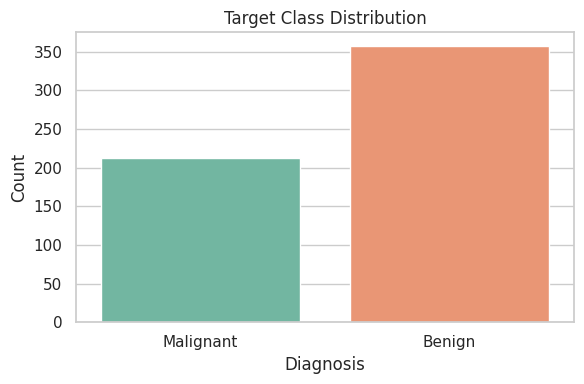

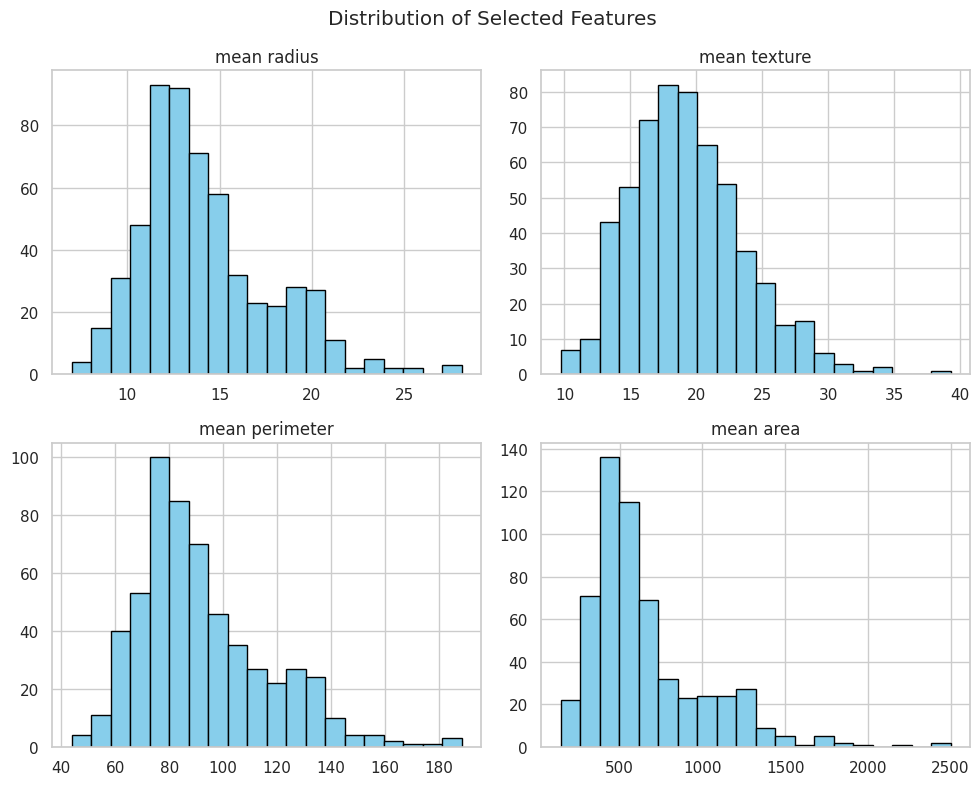


--- PREPROCESSING COMPLETE ---
X_train_scaled shape: (455, 30)
X_test_scaled shape:  (114, 30)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set visual style
sns.set_theme(style="whitegrid")

# ==========================================
# POINT 1: LOAD DATASET & EDA
# ==========================================

# 1. Load raw dataset from sklearn
data = load_breast_cancer()

# 2. Convert features into a pandas DataFrame
X_df = pd.DataFrame(data.data, columns=data.feature_names)

# 3. Extract target labels
y_series = pd.Series(data.target, name='target')

# 4. Combine features and target into one DataFrame
df = pd.concat([X_df, y_series], axis=1)

# 5. Map numeric target values (0 = Malignant, 1 = Benign)
df['target_name'] = df['target'].map({0: 'Malignant', 1: 'Benign'})

# 6. Display first few rows
print("--- FIRST 5 ROWS ---")
print(df.head())

# 7. Check for missing values
print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

# 8. Check target class distribution (counts)
print("\n--- CLASS DISTRIBUTION ---")
print(df['target_name'].value_counts())

# 9. Plot target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target_name', hue='target_name', palette='Set2', legend=False)
plt.title('Target Class Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# 10. Plot feature distributions (histograms)
sample_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area']
df[sample_features].hist(bins=20, figsize=(10, 8), color='skyblue', edgecolor='black')
plt.suptitle('Distribution of Selected Features')
plt.tight_layout()
plt.show()

# ==========================================
# POINT 2: DATA PREPROCESSING
# ==========================================

# 1. Split features (X) and labels (y)
X = data.data
y = data.target

# 2. Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Standardize features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n--- PREPROCESSING COMPLETE ---")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape:  {X_test_scaled.shape}")